# 04 — Machine Learning Model Training

## Objective

Train and evaluate regression models that predict EGFR inhibitory activity (pIC50) from molecular structure.

Models will be evaluated using:
- R²
- RMSE
- MAE

Two molecular feature representations will be investigated:
1. RDKit physicochemical descriptors
2. Morgan molecular fingerprints

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

RANDOM_STATE = 42

In [2]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

print("Processed data directory:")
print(PROCESSED_DATA_DIR)

print("\nFiles:")
for file in PROCESSED_DATA_DIR.iterdir():
    print(file.name)

Processed data directory:
/Users/gracescanlan/Desktop/egfr-ml-drug-discovery/data/processed

Files:
egfr_molecule_activity_with_smiles.csv
egfr_molecular_descriptors.csv
egfr_molecular_features.csv
egfr_morgan_fingerprints.npz


## Load Molecular Features

The molecular feature dataset contains the experimental pIC50 values and physicochemical descriptors calculated for each EGFR compound.

In [3]:
features_path = PROCESSED_DATA_DIR / "egfr_molecular_features.csv"

df = pd.read_csv(features_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10381, 11)


,molecule_chembl_id,canonical_smiles,pIC50,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtomCount
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,4.275724,377.444,4.6822,64.63,1,3,4,4,27
1,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,5.540608,197.190,0.0522,103.78,4,4,3,1,14
2,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,6.339419,346.821,5.0126,50.70,1,4,4,4,25
3,CHEMBL1016,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,5.484537,440.463,4.0286,118.81,2,6,7,5,33
4,CHEMBL101683,O=C(Nc1ccc(Cl)cc1)c1ccccc1NCc1ccncc1,5.136677,337.810,4.5994,54.02,2,3,5,3,24


In [4]:
print(df.columns.tolist())

['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'HeavyAtomCount']


In [5]:
descriptor_cols = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount",
    "HeavyAtomCount"
]

X = df[descriptor_cols]
y = df["pIC50"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (10381, 8)
y shape: (10381,)


,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,HeavyAtomCount
0,377.444,4.6822,64.63,1,3,4,4,27
1,197.190,0.0522,103.78,4,4,3,1,14
2,346.821,5.0126,50.70,1,4,4,4,25
3,440.463,4.0286,118.81,2,6,7,5,33
4,337.810,4.5994,54.02,2,3,5,3,24


## Train-Test Split

The dataset was divided into training and testing sets using an 80/20 split.
The training set was used to develop the models, while the test set was
reserved for evaluating performance on unseen compounds.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training compounds:", X_train.shape[0])
print("Testing compounds:", X_test.shape[0])

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training compounds: 8304
Testing compounds: 2077

Training feature shape: (8304, 8)
Testing feature shape: (2077, 8)


## Baseline Model — Linear Regression

A multiple linear regression model was trained as a baseline for predicting
pIC50 from the eight physicochemical molecular descriptors.

In [7]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Linear regression training complete.")

Linear regression training complete.


In [8]:
linear_r2 = r2_score(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_mae = mean_absolute_error(y_test, y_pred_linear)

print("Linear Regression Performance")
print("-----------------------------")
print(f"R²:   {linear_r2:.3f}")
print(f"RMSE: {linear_rmse:.3f}")
print(f"MAE:  {linear_mae:.3f}")

Linear Regression Performance
-----------------------------
R²:   0.136
RMSE: 1.207
MAE:  0.976


## Random Forest Regression

A Random Forest regression model was trained to capture nonlinear relationships
between molecular physicochemical properties and EGFR inhibitory activity.
Performance was evaluated on the same held-out test set used for the linear
regression baseline.

In [9]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest training complete.")

Random Forest training complete.


In [10]:
rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print(f"R²:   {rf_r2:.3f}")
print(f"RMSE: {rf_rmse:.3f}")
print(f"MAE:  {rf_mae:.3f}")

Random Forest Performance
-------------------------
R²:   0.419
RMSE: 0.989
MAE:  0.749


## Morgan Fingerprint Model

A Random Forest regression model was trained using 2,048-bit Morgan molecular
fingerprints to determine whether structural information improves prediction
of EGFR inhibitory activity compared with physicochemical descriptors alone.

In [44]:
fingerprint_data = np.load(
    PROCESSED_DATA_DIR / "egfr_morgan_fingerprints.npz",
    allow_pickle=True
)

fingerprint_array = fingerprint_data["fingerprints"]

print("Fingerprint matrix:", fingerprint_array.shape)
print("Descriptor dataset:", df.shape)

Fingerprint matrix: (10381, 2048)
Descriptor dataset: (10381, 12)


In [12]:
# Extract Morgan fingerprints and matching pIC50 values
X_fp = fingerprints["fingerprints"]
y_fp = fingerprints["pIC50"]

print("Fingerprint matrix shape:", X_fp.shape)
print("Target shape:", y_fp.shape)

print("\nNumber of molecules:", len(y_fp))
print("Fingerprint bits per molecule:", X_fp.shape[1])

Fingerprint matrix shape: (10381, 2048)
Target shape: (10381,)

Number of molecules: 10381
Fingerprint bits per molecule: 2048


In [13]:
X_fp_train, X_fp_test, y_fp_train, y_fp_test = train_test_split(
    X_fp,
    y_fp,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training molecules:", X_fp_train.shape[0])
print("Testing molecules:", X_fp_test.shape[0])
print("Number of fingerprint features:", X_fp_train.shape[1])

Training molecules: 8304
Testing molecules: 2077
Number of fingerprint features: 2048


In [14]:
rf_fp_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_fp_model.fit(X_fp_train, y_fp_train)

y_pred_rf_fp = rf_fp_model.predict(X_fp_test)

print("Fingerprint Random Forest training complete.")

Fingerprint Random Forest training complete.


In [15]:
rf_fp_r2 = r2_score(y_fp_test, y_pred_rf_fp)
rf_fp_rmse = np.sqrt(mean_squared_error(y_fp_test, y_pred_rf_fp))
rf_fp_mae = mean_absolute_error(y_fp_test, y_pred_rf_fp)

print("Morgan Fingerprint Random Forest Performance")
print("--------------------------------------------")
print(f"R²:   {rf_fp_r2:.3f}")
print(f"RMSE: {rf_fp_rmse:.3f}")
print(f"MAE:  {rf_fp_mae:.3f}")

Morgan Fingerprint Random Forest Performance
--------------------------------------------
R²:   0.721
RMSE: 0.685
MAE:  0.506


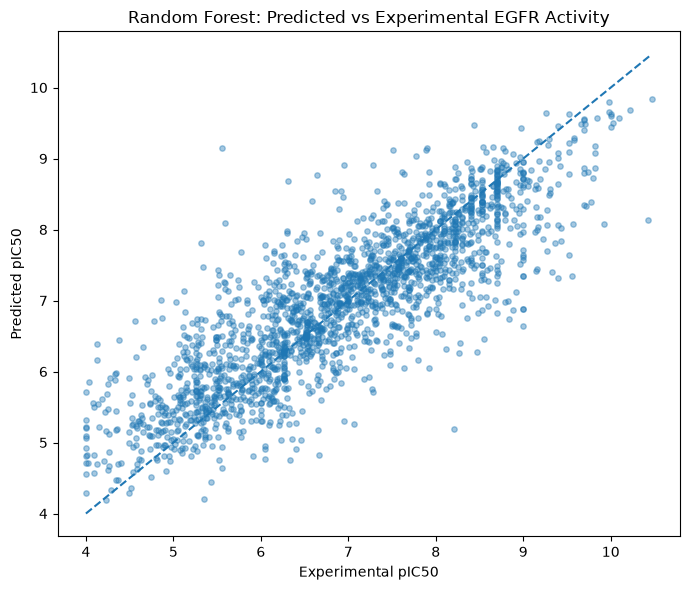

In [16]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_fp_test,
    y_pred_rf_fp,
    alpha=0.4,
    s=15
)

min_val = min(y_fp_test.min(), y_pred_rf_fp.min())
max_val = max(y_fp_test.max(), y_pred_rf_fp.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Experimental pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Random Forest: Predicted vs Experimental EGFR Activity")

plt.tight_layout()
plt.show()

## Build combined feature matrix

In [20]:
fp_ids = fingerprints["molecule_chembl_id"]

print("Fingerprint molecules:", len(fp_ids))
print("Descriptor molecules:", len(df))

print(
    "Molecule order matches:",
    np.array_equal(
        fp_ids.astype(str),
        df["molecule_chembl_id"].astype(str).values
    )
)

Fingerprint molecules: 10381
Descriptor molecules: 10381
Molecule order matches: True


In [21]:
X_descriptors = df[descriptor_cols].values

X_combined = np.hstack([
    X_fp,
    X_descriptors
])

y_combined = y_fp

print("Combined feature matrix:", X_combined.shape)
print("Target:", y_combined.shape)

Combined feature matrix: (10381, 2056)
Target: (10381,)


In [22]:
X_comb_train, X_comb_test, y_comb_train, y_comb_test = train_test_split(
    X_combined,
    y_combined,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training:", X_comb_train.shape)
print("Testing:", X_comb_test.shape)

Training: (8304, 2056)
Testing: (2077, 2056)


In [23]:
rf_combined_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_combined_model.fit(X_comb_train, y_comb_train)

y_pred_combined = rf_combined_model.predict(X_comb_test)

print("Combined Random Forest training complete.")

Combined Random Forest training complete.


In [24]:
combined_r2 = r2_score(y_comb_test, y_pred_combined)

combined_rmse = np.sqrt(
    mean_squared_error(y_comb_test, y_pred_combined)
)

combined_mae = mean_absolute_error(
    y_comb_test,
    y_pred_combined
)

print("Combined Random Forest Performance")
print("----------------------------------")
print(f"R²:   {combined_r2:.3f}")
print(f"RMSE: {combined_rmse:.3f}")
print(f"MAE:  {combined_mae:.3f}")

Combined Random Forest Performance
----------------------------------
R²:   0.709
RMSE: 0.700
MAE:  0.517


## Compare models

In [25]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression (Descriptors)",
        "Random Forest (Descriptors)",
        "Random Forest (Morgan FP)",
        "Random Forest (Morgan FP + Descriptors)"
    ],
    "R2": [
        linear_r2,
        rf_r2,
        rf_fp_r2,
        combined_r2
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        rf_fp_rmse,
        combined_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        rf_fp_mae,
        combined_mae
    ]
})

model_results.round(3)

,Model,R2,RMSE,MAE
0,Linear Regression (Descriptors),0.136,1.207,0.976
1,Random Forest (Descriptors),0.419,0.989,0.749
2,Random Forest (Morgan FP),0.721,0.685,0.506
3,Random Forest (Morgan FP + Descriptors),0.709,0.700,0.517


In [26]:
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

model_results.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison saved.")

Model comparison saved.


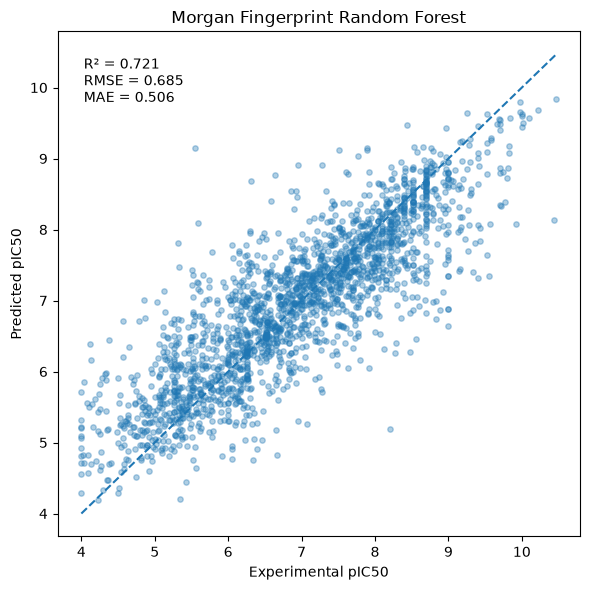

In [27]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_fp_test,
    y_pred_rf_fp,
    alpha=0.35,
    s=15
)

plot_min = min(y_fp_test.min(), y_pred_rf_fp.min())
plot_max = max(y_fp_test.max(), y_pred_rf_fp.max())

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--"
)

plt.xlabel("Experimental pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Morgan Fingerprint Random Forest")

plt.text(
    0.05,
    0.95,
    f"R² = {rf_fp_r2:.3f}\nRMSE = {rf_fp_rmse:.3f}\nMAE = {rf_fp_mae:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "rf_morgan_predicted_vs_experimental.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5-Fold Cross-Validation

Five-fold cross-validation was performed on the Morgan fingerprint Random Forest
to evaluate the stability and generalizability of model performance across
multiple training and validation subsets.

In [28]:
from sklearn.model_selection import KFold, cross_validate

In [29]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_cv_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [30]:
cv_results = cross_validate(
    rf_cv_model,
    X_fp,
    y_fp,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error"
    },
    n_jobs=1,
    return_train_score=False
)

print("Cross-validation complete.")

Cross-validation complete.


In [31]:
cv_r2 = cv_results["test_r2"]
cv_mae = -cv_results["test_mae"]
cv_rmse = np.sqrt(-cv_results["test_mse"])

cv_summary = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "R2": cv_r2,
    "RMSE": cv_rmse,
    "MAE": cv_mae
})

cv_summary.round(3)

,Fold,R2,RMSE,MAE
0,1,0.720,0.687,0.507
1,2,0.731,0.678,0.491
2,3,0.702,0.725,0.517
3,4,0.701,0.710,0.517
4,5,0.701,0.708,0.517


In [32]:
print("5-Fold Cross-Validation Performance")
print("-----------------------------------")

print(
    f"R²:   {cv_r2.mean():.3f} ± {cv_r2.std():.3f}"
)

print(
    f"RMSE: {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}"
)

print(
    f"MAE:  {cv_mae.mean():.3f} ± {cv_mae.std():.3f}"
)

5-Fold Cross-Validation Performance
-----------------------------------
R²:   0.711 ± 0.012
RMSE: 0.702 ± 0.017
MAE:  0.510 ± 0.010


## Scaffold-aware validation

In [36]:
from rdkit.Chem.Scaffolds import MurckoScaffold

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

In [37]:
def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

In [38]:
df["scaffold"] = df["canonical_smiles"].apply(get_scaffold)

print("Molecules:", len(df))
print("Unique scaffolds:", df["scaffold"].nunique())
print("Missing scaffolds:", df["scaffold"].isna().sum())

df[
    ["molecule_chembl_id", "canonical_smiles", "scaffold"]
].head()

Molecules: 10381
Unique scaffolds: 3698
Missing scaffolds: 0


,molecule_chembl_id,canonical_smiles,scaffold
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,c1ccc(-c2nc(-c3ccccc3)c(-c3ccncc3)[nH]2)cc1
1,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,c1ccccc1
2,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,c1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1
3,CHEMBL1016,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...,c1ccc(-c2nnn[nH]2)c(-c2ccc(Cn3cnc4ccccc43)cc2)c1
4,CHEMBL101683,O=C(Nc1ccc(Cl)cc1)c1ccccc1NCc1ccncc1,O=C(Nc1ccccc1)c1ccccc1NCc1ccncc1


### Inspect scaffold sizes

In [39]:
scaffold_counts = (
    df["scaffold"]
    .value_counts()
    .reset_index()
)

scaffold_counts.columns = ["scaffold", "molecule_count"]

scaffold_counts.head(10)

,scaffold,molecule_count
0,c1ccc(Nc2ncnc3ccccc23)cc1,591
1,c1ccc(Nc2ccnc(Nc3ccccc3)n2)cc1,125
2,c1ccc(Nc2nccc(-c3c[nH]c4ccccc34)n2)cc1,117
3,C1=C(C(Nc2ccc3ncccc3c2)c2cccnc2)NNN1C1CC1,117
4,c1ccc(CNc2ncnc3[nH]c(-c4ccccc4)cc23)cc1,94
5,c1ccc(Nc2ccnc3ccccc23)cc1,92
6,c1ccc(Nc2ncnc3ccncc23)cc1,70
7,c1ccc(Nc2ncnc3cnccc23)cc1,66
8,c1ccc(-c2n[nH]c3ncncc23)cc1,65
9,c1ccc(Oc2ccnc(Nc3ccc(N4CCNCC4)cc3)n2)cc1,57


In [40]:
print(
    "Median molecules per scaffold:",
    scaffold_counts["molecule_count"].median()
)

print(
    "Largest scaffold group:",
    scaffold_counts["molecule_count"].max()
)

Median molecules per scaffold: 1.0
Largest scaffold group: 591


### Scaffold-Based Train/Test Split

Molecules were separated according to their Bemis–Murcko scaffolds to evaluate model performance on structurally distinct compounds. All molecules sharing the same scaffold were assigned to the same partition, preventing scaffold overlap between the training and test sets.

In [41]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["scaffold"]

scaffold_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    scaffold_split.split(
        df,
        groups=groups
    )
)

print("Training molecules:", len(train_idx))
print("Test molecules:", len(test_idx))

print(
    "Training fraction:",
    round(len(train_idx) / len(df), 3)
)

print(
    "Test fraction:",
    round(len(test_idx) / len(df), 3)
)

Training molecules: 8416
Test molecules: 1965
Training fraction: 0.811
Test fraction: 0.189


In [42]:
train_scaffolds = set(df.iloc[train_idx]["scaffold"])
test_scaffolds = set(df.iloc[test_idx]["scaffold"])

shared_scaffolds = train_scaffolds.intersection(test_scaffolds)

print("Training scaffolds:", len(train_scaffolds))
print("Test scaffolds:", len(test_scaffolds))
print("Shared scaffolds:", len(shared_scaffolds))

Training scaffolds: 2958
Test scaffolds: 740
Shared scaffolds: 0


In [45]:
X_scaffold_train = fingerprint_array[train_idx]
X_scaffold_test = fingerprint_array[test_idx]

y_scaffold_train = df.iloc[train_idx]["pIC50"].values
y_scaffold_test = df.iloc[test_idx]["pIC50"].values

print("Training X:", X_scaffold_train.shape)
print("Test X:", X_scaffold_test.shape)
print("Training y:", y_scaffold_train.shape)
print("Test y:", y_scaffold_test.shape)

Training X: (8416, 2048)
Test X: (1965, 2048)
Training y: (8416,)
Test y: (1965,)


In [46]:
rf_scaffold = RandomForestRegressor(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_scaffold.fit(
    X_scaffold_train,
    y_scaffold_train
)

y_pred_scaffold = rf_scaffold.predict(X_scaffold_test)

print("Scaffold-split Random Forest training complete.")

Scaffold-split Random Forest training complete.


In [47]:
scaffold_r2 = r2_score(
    y_scaffold_test,
    y_pred_scaffold
)

scaffold_rmse = np.sqrt(
    mean_squared_error(
        y_scaffold_test,
        y_pred_scaffold
    )
)

scaffold_mae = mean_absolute_error(
    y_scaffold_test,
    y_pred_scaffold
)

print("Scaffold-Split Random Forest Performance")
print("----------------------------------------")
print(f"R²:   {scaffold_r2:.3f}")
print(f"RMSE: {scaffold_rmse:.3f}")
print(f"MAE:  {scaffold_mae:.3f}")

Scaffold-Split Random Forest Performance
----------------------------------------
R²:   0.619
RMSE: 0.784
MAE:  0.584


## Neural Network Model

A multilayer perceptron (MLP) neural network was trained to evaluate whether a more flexible nonlinear model could improve prediction of EGFR inhibitory activity. The model used the 2,048-bit Morgan molecular fingerprints as input features and pIC50 as the continuous target variable. The network consisted of three hidden layers containing 256, 128, and 64 neurons with ReLU activation. The Adam optimizer and early stopping were used during training to reduce overfitting. Model performance was evaluated using R², RMSE, and MAE and compared with the Random Forest models.

In [48]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [49]:
print("Training X:", X_fp_train.shape)
print("Test X:", X_fp_test.shape)
print("Training y:", y_fp_train.shape)
print("Test y:", y_fp_test.shape)

Training X: (8304, 2048)
Test X: (2077, 2048)
Training y: (8304,)
Test y: (2077,)


In [50]:
nn_model = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
    verbose=True
)

In [51]:
nn_model.fit(X_fp_train, y_fp_train)

Iteration 1, loss = 1.86597741
Validation score: 0.488416
Iteration 2, loss = 0.35425145
Validation score: 0.586554
Iteration 3, loss = 0.24999772
Validation score: 0.634046
Iteration 4, loss = 0.18482050
Validation score: 0.651974
Iteration 5, loss = 0.14670959
Validation score: 0.669153
Iteration 6, loss = 0.11620246
Validation score: 0.666241
Iteration 7, loss = 0.10350255
Validation score: 0.685672
Iteration 8, loss = 0.08621455
Validation score: 0.682133
Iteration 9, loss = 0.07516452
Validation score: 0.680239
Iteration 10, loss = 0.06990987
Validation score: 0.662776
Iteration 11, loss = 0.06037343
Validation score: 0.684523
Iteration 12, loss = 0.05513386
Validation score: 0.674378
Iteration 13, loss = 0.05332086
Validation score: 0.662517
Iteration 14, loss = 0.05108255
Validation score: 0.679770
Iteration 15, loss = 0.04746019
Validation score: 0.665667
Iteration 16, loss = 0.04630909
Validation score: 0.673355
Iteration 17, loss = 0.04461585
Validation score: 0.682501
Iterat

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(256, ...)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",64
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",15
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001


In [52]:
y_pred_nn = nn_model.predict(X_fp_test)

In [53]:
nn_r2 = r2_score(y_fp_test, y_pred_nn)

nn_rmse = np.sqrt(
    mean_squared_error(y_fp_test, y_pred_nn)
)

nn_mae = mean_absolute_error(
    y_fp_test, y_pred_nn
)

print("Neural Network Performance")
print("--------------------------")
print(f"R²:   {nn_r2:.3f}")
print(f"RMSE: {nn_rmse:.3f}")
print(f"MAE:  {nn_mae:.3f}")

Neural Network Performance
--------------------------
R²:   0.637
RMSE: 0.782
MAE:  0.586


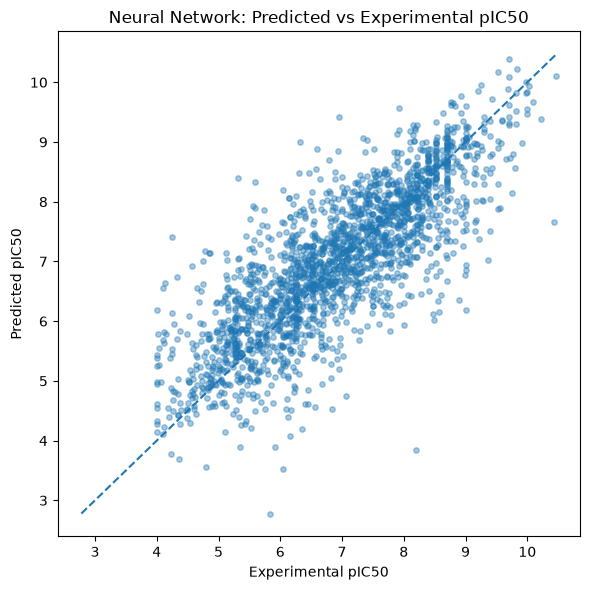

In [54]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_fp_test,
    y_pred_nn,
    alpha=0.4,
    s=15
)

min_val = min(y_fp_test.min(), y_pred_nn.min())
max_val = max(y_fp_test.max(), y_pred_nn.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Experimental pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Neural Network: Predicted vs Experimental pIC50")

plt.tight_layout()
plt.show()

### Neural Network scaffold split test

In [55]:
nn_scaffold_model = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=RANDOM_STATE
)

nn_scaffold_model.fit(
    X_scaffold_train,
    y_scaffold_train
)

y_pred_nn_scaffold = nn_scaffold_model.predict(
    X_scaffold_test
)

In [56]:
nn_scaffold_r2 = r2_score(
    y_scaffold_test,
    y_pred_nn_scaffold
)

nn_scaffold_rmse = np.sqrt(
    mean_squared_error(
        y_scaffold_test,
        y_pred_nn_scaffold
    )
)

nn_scaffold_mae = mean_absolute_error(
    y_scaffold_test,
    y_pred_nn_scaffold
)

print("Scaffold-Split Neural Network Performance")
print("-----------------------------------------")
print(f"R²:   {nn_scaffold_r2:.3f}")
print(f"RMSE: {nn_scaffold_rmse:.3f}")
print(f"MAE:  {nn_scaffold_mae:.3f}")

Scaffold-Split Neural Network Performance
-----------------------------------------
R²:   0.500
RMSE: 0.898
MAE:  0.673


## Final Model Performance Comparison

Performance metrics from all regression models and validation strategies were consolidated to compare predictive accuracy and generalizability. The results were used to select the final model for external compound screening.

In [4]:
import json
import re
import pandas as pd
from pathlib import Path

notebook_path = Path("04_model_training.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

results = []

pattern = re.compile(
    r"R[²2]\s*:\s*([+-]?\d*\.?\d+)"
    r".*?RMSE\s*:\s*([+-]?\d*\.?\d+)"
    r".*?MAE\s*:\s*([+-]?\d*\.?\d+)",
    re.IGNORECASE | re.DOTALL
)

for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    output_text = ""

    for output in cell.get("outputs", []):
        if "text" in output:
            output_text += "".join(output["text"]) + "\n"

        data = output.get("data", {})
        if "text/plain" in data:
            output_text += "".join(data["text/plain"]) + "\n"

    matches = pattern.findall(output_text)

    for match in matches:
        results.append({
            "Cell": i,
            "R²": float(match[0]),
            "RMSE": float(match[1]),
            "MAE": float(match[2])
        })

metrics_df = pd.DataFrame(results)

display(metrics_df)

,Cell,R²,RMSE,MAE
0,11,0.136,1.207,0.976
1,14,0.419,0.989,0.749
2,20,0.721,0.685,0.506
3,27,0.709,0.700,0.517
4,37,0.711,0.702,0.510
5,50,0.619,0.784,0.584
6,57,0.637,0.782,0.586
7,61,0.500,0.898,0.673


In [5]:
model_labels = {
    11: ("Linear Regression", "Descriptors", "Random split"),
    14: ("Random Forest", "Descriptors", "Random split"),
    20: ("Random Forest", "Morgan fingerprints", "Random split"),
    27: ("Random Forest", "FP + descriptors", "Random split"),
    37: ("Random Forest", "Morgan fingerprints", "5-fold CV"),
    50: ("Random Forest", "Morgan fingerprints", "Scaffold split"),
    57: ("Neural Network", "Morgan fingerprints", "Random split"),
    61: ("Neural Network", "Morgan fingerprints", "Scaffold split")
}

table1 = metrics_df.copy()

table1[["Model", "Features", "Evaluation"]] = table1["Cell"].apply(
    lambda cell: pd.Series(model_labels.get(cell, ("Unknown", "Unknown", "Unknown")))
)

table1 = table1[
    ["Model", "Features", "Evaluation", "R²", "RMSE", "MAE"]
]

display(table1)

,Model,Features,Evaluation,R²,RMSE,MAE
0,Linear Regression,Descriptors,Random split,0.136,1.207,0.976
1,Random Forest,Descriptors,Random split,0.419,0.989,0.749
2,Random Forest,Morgan fingerprints,Random split,0.721,0.685,0.506
3,Random Forest,FP + descriptors,Random split,0.709,0.700,0.517
4,Random Forest,Morgan fingerprints,5-fold CV,0.711,0.702,0.510
5,Random Forest,Morgan fingerprints,Scaffold split,0.619,0.784,0.584
6,Neural Network,Morgan fingerprints,Random split,0.637,0.782,0.586
7,Neural Network,Morgan fingerprints,Scaffold split,0.500,0.898,0.673


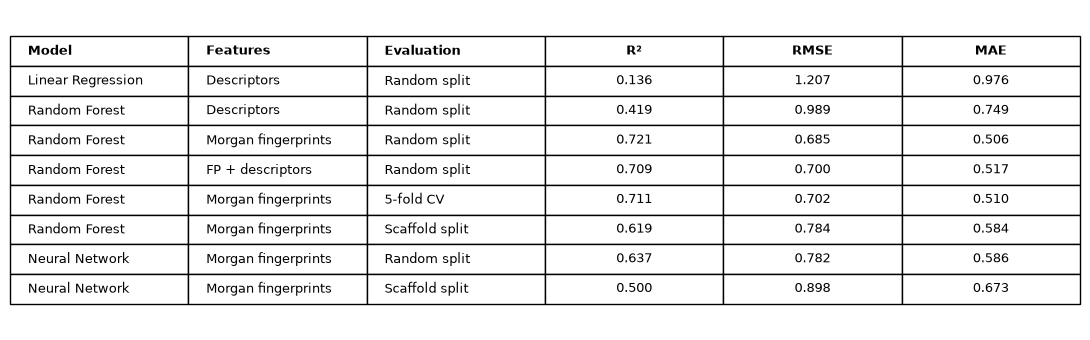

Saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/table1_model_performance.png


In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axis("off")

display_table = table1.copy()

for col in ["R²", "RMSE", "MAE"]:
    display_table[col] = display_table[col].map(lambda x: f"{x:.3f}")

tbl = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.5)

for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
    if col in [0, 1, 2]:
        cell.get_text().set_ha("left")

plt.tight_layout()

from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

output_path = PROJECT_ROOT / "figures" / "table1_model_performance.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

In [12]:
import json
from pathlib import Path

notebook_path = Path("04_model_training.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Original cross-validation cell
cell = notebook["cells"][37]

print("CROSS-VALIDATION CODE:")
print("".join(cell.get("source", [])))

print("\nCROSS-VALIDATION OUTPUT:")

for output in cell.get("outputs", []):
    if "text" in output:
        print("".join(output["text"]))

    data = output.get("data", {})
    if "text/plain" in data:
        print("".join(data["text/plain"]))

CROSS-VALIDATION CODE:
print("5-Fold Cross-Validation Performance")
print("-----------------------------------")

print(
    f"R²:   {cv_r2.mean():.3f} ± {cv_r2.std():.3f}"
)

print(
    f"RMSE: {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}"
)

print(
    f"MAE:  {cv_mae.mean():.3f} ± {cv_mae.std():.3f}"
)

CROSS-VALIDATION OUTPUT:
5-Fold Cross-Validation Performance
-----------------------------------
R²:   0.711 ± 0.012
RMSE: 0.702 ± 0.017
MAE:  0.510 ± 0.010



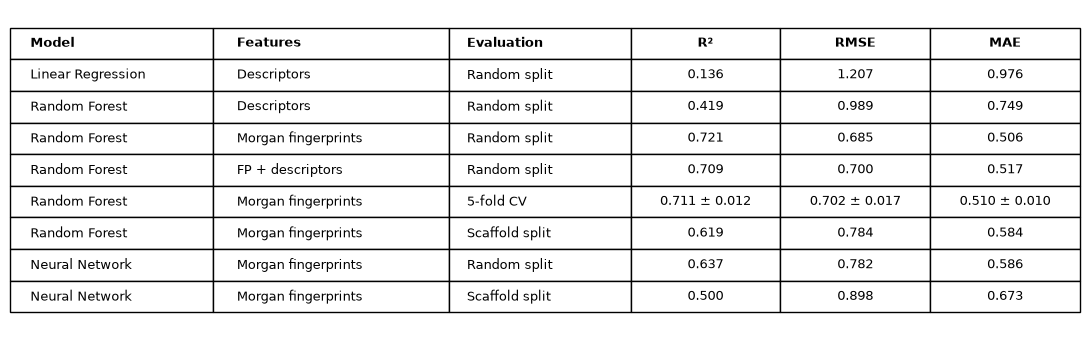

Saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/table1_model_performance.png


,Model,Features,Evaluation,R²,RMSE,MAE
0,Linear Regression,Descriptors,Random split,0.136,1.207,0.976
1,Random Forest,Descriptors,Random split,0.419,0.989,0.749
2,Random Forest,Morgan fingerprints,Random split,0.721,0.685,0.506
3,Random Forest,FP + descriptors,Random split,0.709,0.700,0.517
4,Random Forest,Morgan fingerprints,5-fold CV,0.711 ± 0.012,0.702 ± 0.017,0.510 ± 0.010
5,Random Forest,Morgan fingerprints,Scaffold split,0.619,0.784,0.584
6,Neural Network,Morgan fingerprints,Random split,0.637,0.782,0.586
7,Neural Network,Morgan fingerprints,Scaffold split,0.500,0.898,0.673


In [15]:
import re
import json
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

# Copy the previously extracted model performance table
final_table = table1.copy()

# Extract cross-validation results from the saved notebook
with open("04_model_training.ipynb", "r", encoding="utf-8") as f:
    notebook = json.load(f)

cv_cell = notebook["cells"][37]

cv_output = ""

for output in cv_cell.get("outputs", []):
    if "text" in output:
        cv_output += "".join(output["text"])

# Extract mean ± SD directly from the output
for metric in ["R²", "RMSE", "MAE"]:
    pattern = rf"{re.escape(metric)}:\s*([\d.]+)\s*±\s*([\d.]+)"
    match = re.search(pattern, cv_output)

    if match:
        final_table[metric] = final_table[metric].astype(object)

        final_table.loc[
            final_table["Evaluation"] == "5-fold CV",
            metric
        ] = f"{match.group(1)} ± {match.group(2)}"

# Format remaining metrics to three decimals
for metric in ["R²", "RMSE", "MAE"]:
    final_table[metric] = final_table[metric].apply(
        lambda x: f"{x:.3f}" if isinstance(x, (int, float)) else x
    )

# Create the figure
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axis("off")

tbl = ax.table(
    cellText=final_table.values,
    colLabels=final_table.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.19, 0.22, 0.17, 0.14, 0.14, 0.14]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.6)

for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
    if col in [0, 1, 2]:
        cell.get_text().set_ha("left")

plt.tight_layout()

# Save the actual figure
output_path = PROJECT_ROOT / "figures" / "table1_model_performance.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", output_path)

display(final_table)